PHASE4: DEFINE FX STRESS

Step7: Define a Target

In [17]:
import pandas as pd

# ============================================================
# STEP 7.1 - Volatility thresholds
# ============================================================

df_volatility = pd.read_csv("../data/processed/fx_volatility_30d.csv")
df_returns = pd.read_csv("../data/processed/fx_returns.csv")

volatility_cols = [
    "CNY_vol30",
    "EUR_vol30",
    "INR_vol30",
    "ZAR_vol30",
    "TRY_vol30",
    "JPY_vol30",
    "GBP_vol30",
    "BRL_vol30",
    "AUD_vol30"
]

# Calculate percentile thresholds
vol_percentiles = (
    df_volatility[volatility_cols]
    .quantile([0.75, 0.90, 0.95, 0.99])
    .T
)

# Display as percentages
print(vol_percentiles.map(lambda x: f"{x:.2%}"))

            0.75   0.90   0.95   0.99
CNY_vol30  0.26%  0.36%  0.40%  0.62%
EUR_vol30  0.55%  0.69%  0.77%  0.92%
INR_vol30  0.36%  0.43%  0.46%  0.64%
ZAR_vol30  1.05%  1.26%  1.43%  1.63%
TRY_vol30  0.84%  1.22%  1.75%  4.79%
JPY_vol30  0.67%  0.84%  0.94%  1.23%
GBP_vol30  0.60%  0.73%  0.86%  1.52%
BRL_vol30  1.11%  1.35%  1.49%  2.01%
AUD_vol30  0.71%  0.88%  0.99%  1.25%


### Step 7.2 — Standardizing Volatility Across Currencies

**Objective:** Make volatility levels comparable across the nine currencies by measuring how unusual each currency's volatility is relative to its own historical distribution.

In Step 7.1, we found substantial differences in historical volatility thresholds. For example, the 95th-percentile volatility is **0.40% for CNY** but **1.75% for TRY**. Therefore, applying the same absolute volatility threshold to every currency could misrepresent the level of risk.

To address this, we convert each currency's 30-day rolling volatility into a **historical percentile rank** between 0 and 1.

- A percentile rank near **0.50** indicates volatility around the middle of its historical distribution.
- A rank near **0.90** indicates unusually high volatility.
- A rank near **0.95 or above** indicates volatility near the upper tail of its historical distribution.

This transformation allows us to compare currencies on a common relative scale, regardless of their typical volatility levels.

**Expected outcome:** A new dataset containing standardized volatility percentile ranks for all nine currencies. These comparable measures will provide the foundation for identifying periods when elevated volatility occurs across multiple currencies simultaneously.

**Methodological limitation:** Using the full historical sample to calculate percentile ranks incorporates information from future observations when evaluating past dates. This is acceptable for exploratory historical analysis, but a past-only approach will be required when developing a real-time early-warning system.

In [18]:

# ============================================================
# STEP 7.2 - Standardize volatality across currencies
# ============================================================

# Create a new dataframe without modifying original volatility data
df_vol_percentile = df_volatility[["Day"]].copy()

# Calculate historical percentile ranks for each currency
for col in volatility_cols:
    new_col = col.replace("_vol30", "_vol_percentile")
    df_vol_percentile[new_col] = df_volatility[col].rank(pct=True)

# Identify percentile columns
percentile_cols = df_vol_percentile.columns.drop("Day")

# Display summary statistics
summary = df_vol_percentile[percentile_cols].describe()
summary_display = summary.map(lambda x: f"{x:.2%}")

# Display observation counts as integers, not percentages
summary_display.loc["count"] = summary.loc["count"].map(
    lambda x: f"{x:,.0f}"
)

print("Summary statistics:")
print(summary_display)

# Save processed dataset
import os

os.makedirs("../data/processed", exist_ok=True)

df_vol_percentile.to_csv(
    "../data/processed/fx_volatility_percentiles.csv",
    index=False
)

print("\nDataset saved successfully:")
print("../data/processed/fx_volatility_percentiles.csv")

Summary statistics:
      CNY_vol_percentile EUR_vol_percentile INR_vol_percentile  \
count              2,966              2,966              2,966   
mean              50.02%             50.02%             50.02%   
std               28.87%             28.87%             28.87%   
min                0.03%              0.03%              0.03%   
25%               25.03%             25.03%             25.03%   
50%               50.02%             50.02%             50.02%   
75%               75.01%             75.01%             75.01%   
max              100.00%            100.00%            100.00%   

      ZAR_vol_percentile TRY_vol_percentile JPY_vol_percentile  \
count              2,966              2,966              2,966   
mean              50.02%             50.02%             50.02%   
std               28.87%             28.87%             28.87%   
min                0.03%              0.03%              0.03%   
25%               25.03%             25.03%            

In [27]:
# ============================================================
# STEP 7.3 - Measure cross-currency stress
# ============================================================

# Define the volatility percentile columns
percentile_cols = [
    col for col in df_vol_percentile.columns
    if col.endswith("_vol_percentile")
]

# Check that all nine currencies are included
assert len(percentile_cols) == 9, (
    f"Expected 9 currency columns, found {len(percentile_cols)}"
)

# Define the high-volatility threshold
threshold = 0.90

# Identify currencies above their 90th-percentile threshold
high_volatility = df_vol_percentile[percentile_cols] > threshold

# Create the cross-currency stress dataset
df_fx_stress = df_vol_percentile[["Day"]].copy()

# Count currencies experiencing high volatility each day
df_fx_stress["HighVol_Currency_Count"] = high_volatility.sum(axis=1)

# Calculate the proportion of currencies experiencing high volatility
df_fx_stress["HighVol_Currency_Ratio"] = (
    high_volatility.sum(axis=1) / len(percentile_cols)
)

# Display summary statistics
summary = df_fx_stress[
    ["HighVol_Currency_Count", "HighVol_Currency_Ratio"]
].describe()

summary_display = summary.copy()

summary_display["HighVol_Currency_Ratio"] = (
    summary["HighVol_Currency_Ratio"].map(lambda x: f"{x:.2%}")
)
print("\nSummary statistics:")
print(summary_display)

# ============================================================
# SAVE PROCESSED DATASET
# ============================================================

import os

os.makedirs("../data/processed", exist_ok=True)

output_path = "../data/processed/fx_cross_currency_stress.csv"

df_fx_stress.to_csv(output_path, index=False)

print("\nDataset saved successfully:")
print(output_path)


Summary statistics:
       HighVol_Currency_Count HighVol_Currency_Ratio
count             2996.000000             299600.00%
mean                 0.892190                  9.91%
std                  1.421769                 15.80%
min                  0.000000                  0.00%
25%                  0.000000                  0.00%
50%                  0.000000                  0.00%
75%                  1.000000                 11.11%
max                  8.000000                 88.89%

Dataset saved successfully:
../data/processed/fx_cross_currency_stress.csv


In [30]:
# ============================================================
# STEP 7.4 - Construct the initial fx stress indicator
# ============================================================

# Define the volatility percentile columns
percentile_cols = [
    col for col in df_vol_percentile.columns
    if col.endswith("_vol_percentile")
]

# Check that all nine currencies are included
assert len(percentile_cols) == 9, (
    f"Expected 9 currency columns, found {len(percentile_cols)}"
)

# Calculate the average volatility percentile across currencies
df_fx_stress["FX_Stress_Index"] = (
    df_vol_percentile[percentile_cols].mean(axis=1)
)


# Display summary statistics
summary = df_fx_stress["FX_Stress_Index"].describe()

summary_display = summary.map(lambda x: f"{x:.2%}")
summary_display["count"] = f"{summary['count']:.0f}"

print("\nFX Stress Indicator - Summary Statistics:")
print(summary_display)

# ============================================================
# SAVE PROCESSED DATASET
# ============================================================

import os

os.makedirs("../data/processed", exist_ok=True)

df_fx_stress.to_csv(
    "../data/processed/fx_stress_indicator.csv",
    index=False
)

print("\nDataset saved successfully:")
print("../data/processed/fx_stress_indicator.csv")


FX Stress Indicator - Summary Statistics:
count      2966
mean     50.02%
std      17.78%
min       9.64%
25%      36.25%
50%      49.77%
75%      63.76%
max      95.64%
Name: FX_Stress_Index, dtype: str

Dataset saved successfully:
../data/processed/fx_stress_indicator.csv


In [32]:
# ============================================================
# STEP 7.5 - DEFINE CANDIDATE FX STRESS PERIODS
# ============================================================

# Calculate the 90th-percentile threshold using valid observations
stress_threshold = df_fx_stress["FX_Stress_Index"].quantile(0.90)

# Initialize stress flags as missing
df_fx_stress["FX_Stress_Flag"] = float("nan")

# Label only observations with a valid FX Stress Index
valid_index = df_fx_stress["FX_Stress_Index"].notna()

df_fx_stress.loc[valid_index, "FX_Stress_Flag"] = (
    df_fx_stress.loc[valid_index, "FX_Stress_Index"]
    .ge(stress_threshold)
    .astype(int)
)

# Display the threshold
print("FX Stress Index threshold (90th percentile):")
print(f"{stress_threshold:.2%}")

# Summarize valid observations and candidate stress days
total_days = int(valid_index.sum())
stress_days = int(df_fx_stress["FX_Stress_Flag"].sum())
stress_ratio = stress_days / total_days if total_days else float("nan")

print("\nCandidate stress-day summary:")
print(f"Total dataset rows: {len(df_fx_stress):.0f}")
print(f"Valid indicator observations: {total_days:.0f}")
print(f"Candidate stress days: {stress_days:.0f}")
print(f"Candidate stress days (% of valid observations): {stress_ratio:.2%}")
print(f"Missing indicator observations: {(~valid_index).sum():.0f}")

# Display the first 10 observations
print("\nFirst 10 observations:")
print(
    df_fx_stress[
        ["Day", "FX_Stress_Index", "FX_Stress_Flag"]
    ].head(10)
)

# ============================================================
# SAVE PROCESSED DATASET
# ============================================================

df_fx_stress.to_csv(
    "../data/processed/fx_stress_indicator.csv",
    index=False
)

print("\nDataset saved successfully:")
print("../data/processed/fx_stress_indicator.csv")

FX Stress Index threshold (90th percentile):
72.82%

Candidate stress-day summary:
Total dataset rows: 2996
Valid indicator observations: 2966
Candidate stress days: 297
Candidate stress days (% of valid observations): 10.01%
Missing indicator observations: 30

First 10 observations:
          Day  FX_Stress_Index  FX_Stress_Flag
0  2015-01-02              NaN             NaN
1  2015-01-05              NaN             NaN
2  2015-01-06              NaN             NaN
3  2015-01-07              NaN             NaN
4  2015-01-08              NaN             NaN
5  2015-01-09              NaN             NaN
6  2015-01-12              NaN             NaN
7  2015-01-13              NaN             NaN
8  2015-01-14              NaN             NaN
9  2015-01-15              NaN             NaN

Dataset saved successfully:
../data/processed/fx_stress_indicator.csv


Comparison of candidate stress and non-stress days:
                Days Mean_Stress_Index  Mean_HighVol_Currencies  \
FX_Stress_Flag                                                    
0.0             2669            46.68%                 0.560135   
1.0              297            80.01%                 3.966330   

               Mean_HighVol_Ratio  
FX_Stress_Flag                     
0.0                         6.22%  
1.0                        44.07%  


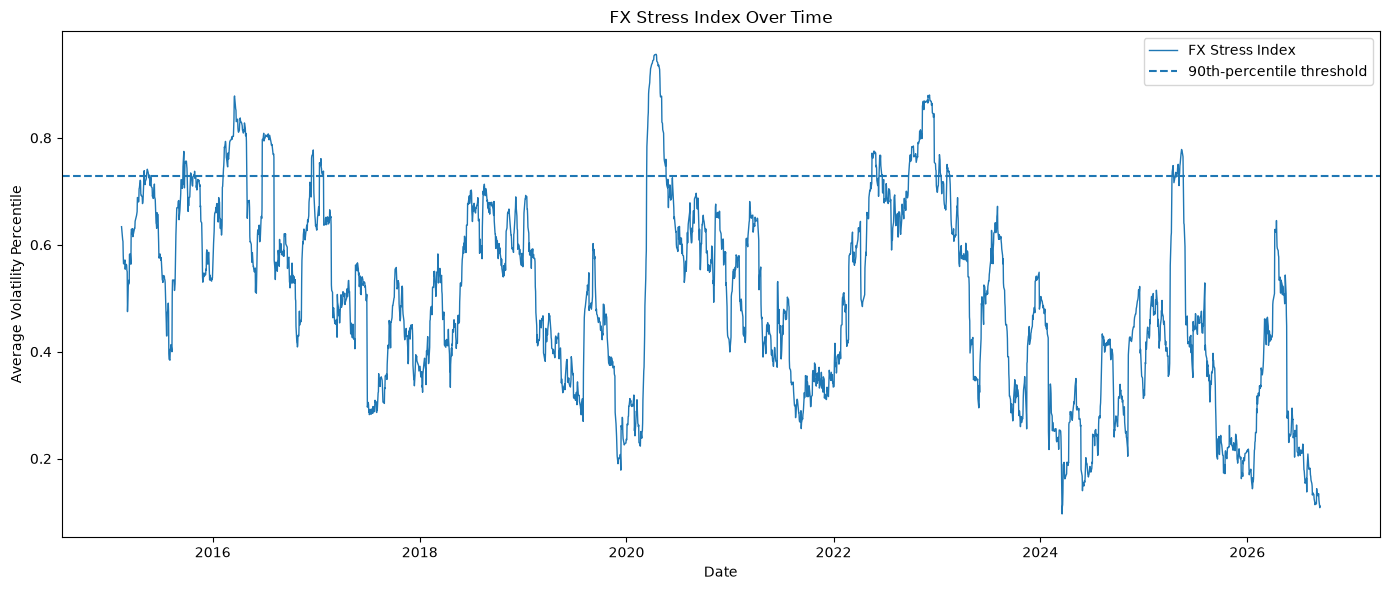

In [33]:
# ============================================================
# STEP 7.6 - VALIDATE CANDIDATE STRESS PERIODS
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

# Convert dates to datetime
df_fx_stress["Day"] = pd.to_datetime(df_fx_stress["Day"])

# Summarize stress and non-stress days
stress_comparison = df_fx_stress.groupby("FX_Stress_Flag").agg(
    Days=("FX_Stress_Index", "count"),
    Mean_Stress_Index=("FX_Stress_Index", "mean"),
    Mean_HighVol_Currencies=("HighVol_Currency_Count", "mean"),
    Mean_HighVol_Ratio=("HighVol_Currency_Ratio", "mean")
)

# Format a readable copy for display
stress_comparison_display = stress_comparison.copy()
stress_comparison_display["Mean_Stress_Index"] = (
    stress_comparison["Mean_Stress_Index"].map(lambda x: f"{x:.2%}")
)
stress_comparison_display["Mean_HighVol_Ratio"] = (
    stress_comparison["Mean_HighVol_Ratio"].map(lambda x: f"{x:.2%}")
)
stress_comparison_display["Days"] = (
    stress_comparison["Days"].map(lambda x: f"{x:.0f}")
)

print("Comparison of candidate stress and non-stress days:")
print(stress_comparison_display)

# Plot the FX Stress Index over time
plt.figure(figsize=(14, 6))
plt.plot(
    df_fx_stress["Day"],
    df_fx_stress["FX_Stress_Index"],
    label="FX Stress Index",
    linewidth=1
)
plt.axhline(
    df_fx_stress["FX_Stress_Index"].quantile(0.90),
    linestyle="--",
    label="90th-percentile threshold"
)
plt.title("FX Stress Index Over Time")
plt.xlabel("Date")
plt.ylabel("Average Volatility Percentile")
plt.legend()
plt.tight_layout()
plt.show()

# Phase 4 — FX Stress Indicator Construction

## Objective

Transform currency-specific rolling volatility into a standardized cross-currency indicator to identify historically elevated FX volatility.

## Steps Completed

1. **Volatility Threshold Analysis:** Examined the 75th, 90th, 95th, and 99th percentiles of 30-day rolling volatility for each of the nine currencies.
2. **Volatility Percentile Standardization:** Converted each currency's volatility into a historical percentile rank, making relative volatility comparable across currencies.
3. **Cross-Currency Stress Measurement:** Counted the currencies exceeding their respective 90th-percentile volatility thresholds each day and calculated their proportion.
4. **FX Stress Indicator Construction:** Calculated the daily average of the nine currency volatility percentile ranks.
5. **Candidate Stress-Day Classification:** Defined candidate stress days as observations at or above the indicator's historical 90th-percentile threshold.
6. **Historical Consistency Check:** Compared the indicator and cross-currency volatility measures between candidate stress and non-stress days and inspected the indicator over time.

## Key Findings

* **FX Stress Index threshold:** 72.82%.
* **Valid indicator observations:** 2,966.
* **Candidate stress days:** 297 (10.01% of valid observations).
* **Mean index on candidate stress days:** 80.01%, compared with 46.68% on non-stress days.
* **Mean number of high-volatility currencies:** 3.97 on candidate stress days, compared with 0.56 on non-stress days.

These results indicate that the initial indicator identifies historical periods associated with elevated relative volatility across multiple currencies.

## Output Files

* `fx_volatility_percentiles.csv` — currency-specific volatility percentile ranks.
* `fx_cross_currency_stress.csv` — daily high-volatility currency counts and ratios.
* `fx_stress_indicator.csv` — FX Stress Index and candidate stress labels.

All files are stored in `../data/processed/`.

## Limitations and Next Steps

The current percentile ranks and stress threshold are calculated using the full historical sample. Consequently, the indicator is suitable for exploratory historical analysis but is not yet validated as a real-time early-warning signal. The candidate labels are defined from the same indicator used in the consistency check and do not independently confirm market crises.

The next phase will develop a past-data-only approach, address look-ahead bias, and evaluate whether the indicator can help identify elevated FX volatility in future, unseen observations.
